# Makine Öğrenmesi Laboratuvarı — Kümeleme ve Parametrik Olmayan Yöntemler

**İstanbul 29 Mayıs Üniversitesi · Makine Öğrenmesi · Uygulama Defteri**

Bu notebook iki parçadan oluşur:

- **Bölüm A – Kümeleme:** 10 kısa, adım adım uygulama + **1 öğrenci görevi (K-A)**
- **Bölüm B – Parametrik olmayan yöntemler:** 7 kısa uygulama + **1 öğrenci görevi (NP-A)**

Her kısa uygulamada açıklamayı oku, hücreyi çalıştır, grafiği yorumla ve **📝 Dene** kısmındaki küçük değişikliği yap. Son iki kapsamlı görevde hazır çözüm yoktur; öğrenciler önceki örneklerden yararlanarak tamamlar.

**Kurulum:** Python 3.10+ ve `numpy`, `pandas`, `matplotlib`, `scipy`, `scikit-learn` gerekir. Eksik paketler için terminalde: `pip install numpy pandas matplotlib scipy scikit-learn`

**Veri:** Bütün veri kümeleri sentetiktir veya scikit-learn içinden gelir. İnternet bağlantısı gerekmez. `random_state=42` ile sonuçlar tekrarlanabilir.

> **EĞİTMEN VERSİYONU — SATIR SATIR AÇIKLAMALI VE ÇÖZÜMLÜ**
> 17 kısa uygulama ve iki kapsamlı görev, her kod satırının üzerinde Türkçe `# ADIM` yorumlarıyla anlatılmıştır. Kapsamlı soruların cevapları yalnızca bu sürümdedir.

## Nasıl çalışmalısın? — Her kod satırında açıklama

Bu güncellenmiş defterde **bütün kısa uygulamaların bütün kod satırlarının hemen üzerinde Türkçe `# ADIM` açıklaması bulunur.** Her adımı okumadan sonraki satıra geçme.

1. Üstteki **Kurulum / Ortak Fonksiyonlar** hücresini çalıştır; değişkenler ve kütüphaneler hazırlanır.
2. Her alıştırmanın **Kavram** bölümünü oku, ardından **`# ADIM ...`** yorumunu takip ederek kodu çalıştır.
3. **📝 Dene** notuna göre bir parametreyi değiştir, grafikte/çıktıda ne değiştiğini gözlemle.
4. K-A ve NP-A kapsamlı görevlerinde yorum satırlarındaki adımları **sırayla koda dönüştür**. Öğrenci sürümünde çözüm bilerek yoktur.
5. Her kapsamlı görevde elde ettiğin grafiği, sayısal sonucu ve iki–üç cümlelik yorumunu teslim et.

**Hatırlatma:** `#` ile başlayan satırlar Python tarafından çalıştırılmaz; kodun ne yaptığını anlatır. `# ÇÖZÜMÜNÜ BURAYA YAZ` satırının altına kendi Python kodunu eklemelisin.

In [1]:
# ADIM 01: NumPy kütüphanesini sayısal hesaplamalar ve diziler için içe aktar.
import numpy as np
# ADIM 02: Pandas kütüphanesini sonuç tablolarını oluşturmak için içe aktar.
import pandas as pd
# ADIM 03: Matplotlib pyplot modülünü grafik çizmek için içe aktar.
import matplotlib.pyplot as plt
# ADIM 04: Sentetik küme, iki ay ve Wine veri kümesi oluşturma işlevlerini yükle.
from sklearn.datasets import make_blobs, make_moons, load_wine
# ADIM 05: Özellikleri ortalaması 0, standart sapması 1 olacak şekilde ölçekleyen sınıfı yükle.
from sklearn.preprocessing import StandardScaler
# ADIM 06: K-Means, DBSCAN, hiyerarşik ve spektral kümeleme algoritmalarını içe aktar.
from sklearn.cluster import KMeans, DBSCAN, AgglomerativeClustering, SpectralClustering
# ADIM 07: Gaussian karışım modelini ve EM tabanlı öğrenmeyi kullanmak için sınıfı yükle.
from sklearn.mixture import GaussianMixture
# ADIM 08: Silhouette, ARI, accuracy ve confusion matrix araçlarını içe aktar.
from sklearn.metrics import silhouette_score, adjusted_rand_score, accuracy_score, ConfusionMatrixDisplay
# ADIM 09: Verileri eğitim, doğrulama ve test kümelerine bölmek için işlevi yükle.
from sklearn.model_selection import train_test_split
# ADIM 10: k-NN sınıflandırma/regresyon, KDE ve LOF sınıflarını içe aktar.
from sklearn.neighbors import KNeighborsClassifier, KNeighborsRegressor, KernelDensity, LocalOutlierFactor
# ADIM 11: Hiyerarşik birleştirme ve dendrogram çizme işlevlerini içe aktar.
from scipy.cluster.hierarchy import linkage, dendrogram

# ADIM 12: Tekrarlanabilir deneyler için genel rastgelelik tohumunu 42 olarak ayarla.
np.random.seed(42)
# ADIM 13: Çizim boyutu, ızgara görünürlüğü, ızgara saydamlığı ve yazı boyutunu varsayılan yap.
plt.rcParams.update({'figure.figsize':(7,4.2), 'axes.grid':True, 'grid.alpha':0.18, 'font.size':10})

# ADIM 14: İki boyutlu küme sonuçlarını gösterecek yardımcı fonksiyonu tanımla.
def cluster_plot(X, labels, title, ax=None, centers=None):
    # ADIM 15: Fonksiyonun amacını belgele: -1 etiketi DBSCAN gürültüsünü belirtir.
    """2 boyutlu küme etiketlerini çizer; -1 gürültü etiketidir."""
    # ADIM 16: Grafik ekseni dışarıdan verilmediyse kendin yeni bir grafik ekseni oluştur.
    if ax is None:
        # ADIM 17: Yeni bir figür ve eksen aç; ekseni ax değişkenine ata.
        _, ax = plt.subplots()
    # ADIM 18: Küme etiketlerini NumPy dizisine dönüştür; karşılaştırmaları kolaylaştır.
    labels = np.asarray(labels)
    # ADIM 19: Aynı veri kümesindeki benzersiz etiketleri sırayla dolaş.
    for lbl in np.unique(labels):
        # ADIM 20: Sıradaki etikete sahip veri noktalarını seçen True/False maskesini hesapla.
        mask = labels == lbl
        # ADIM 21: Etiket -1 ise bu noktaların DBSCAN tarafından gürültü sayıldığını kontrol et.
        if lbl == -1:
            # ADIM 22: Gürültü noktalarını gri çarpılarla çiz; grafikteki açıklama etiketini ekle.
            ax.scatter(X[mask,0], X[mask,1], s=26, c='gray', marker='x', label='Gürültü (-1)')
        # ADIM 23: Etiket -1 değilse normal bir kümeyi çizmek üzere diğer kola geç.
        else:
            # ADIM 24: Seçilen kümeye ait noktaları işaretle, küme numarasını ve saydamlığı belirt.
            ax.scatter(X[mask,0], X[mask,1], s=26, label=f'Küme {lbl}', alpha=.82)
    # ADIM 25: Küme merkezleri verilmişse onları da görselleştirmek üzere kontrol et.
    if centers is not None:
        # ADIM 26: Merkezleri büyük siyah X işaretleriyle çiz; diğer noktalardan ayırt et.
        ax.scatter(centers[:,0], centers[:,1], c='black', marker='X', s=130, label='Merkezler')
    # ADIM 27: Eksen adlarını ve grafiğin başlığını belirle.
    ax.set(xlabel='Özellik 1', ylabel='Özellik 2', title=title)
    # ADIM 28: Renkli kümelerin ve gürültünün açıklamasını (legend) grafiğe ekle.
    ax.legend(fontsize=8, loc='best')
    # ADIM 29: Oluşturulan ekseni geri döndür; başka hücrelerde aynı yordam kullanılabilsin.
    return ax

# ADIM 30: Kurulumun tamamlandığını ekranda bildir.
print('Hazır! Kütüphaneler yüklendi.')

Hazır! Kütüphaneler yüklendi.


---
# BÖLÜM A — KÜMELEME

**Amaç:** Etiketsiz veriyi görselleştirmek; K-Means, Elbow, Silhouette, Agglomerative, DBSCAN, GMM ve Spectral Clustering yöntemlerini adım adım denemek.

> Kümeleme denetimsiz öğrenmedir. `y_true` gibi bilinen etiketleri yalnızca sentetik verilerde sonucu *değerlendirmek* için kullanacağız; modeli eğitirken kullanmayacağız.

## K1 · Veri kümesini oluştur ve gözlemle

**Kavram:** Kümeleme, veri noktalarını benzerliklerine göre gruplar. Aşağıdaki noktaların hangi grupları oluşturduğunu algoritmaya söylemiyoruz.

**📝 Dene:** `cluster_std=0.65` değerini `1.3` yap. Grupların ayrışması nasıl değişti?

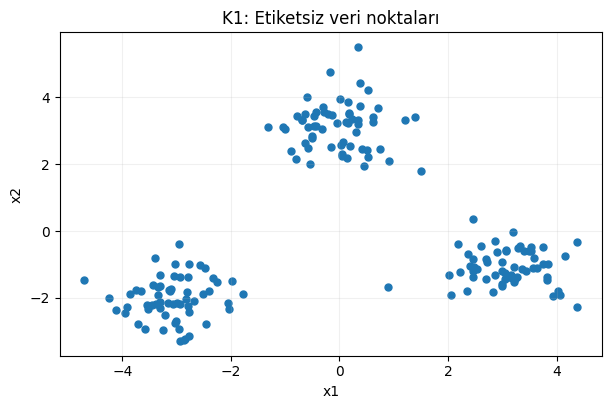

Veri şekli: (180, 2)


In [2]:
# ADIM 01: Make_blobs ile etiketleri de bulunan ama kümelemede etiketlerini kullanmayacağımız noktalar üret.
X_blob, y_blob_ref = make_blobs(
    # ADIM 02: 180 örnek, üç merkez, standart sapma 0.65 ve sabit rastgelelik tohumu belirle.
    n_samples=180, centers=[(-3,-2),(0,3),(3,-1)], cluster_std=0.65, random_state=42)
# ADIM 03: Birinci özelliği yatay, ikinci özelliği dikey eksene yerleştirerek noktaları çiz.
plt.scatter(X_blob[:,0], X_blob[:,1], s=25)
# ADIM 04: Grafiğin başlığı ile henüz sınıf etiketlerinin kullanılmadığını belirt.
plt.title('K1: Etiketsiz veri noktaları')
# ADIM 05: Eksen adlarını yazdır ve grafiği ekranda göster.
plt.xlabel('x1'); plt.ylabel('x2'); plt.show()
# ADIM 06: X_blob matrisinin kaç satır (örnek) ve sütun (özellik) içerdiğini yazdır.
print('Veri şekli:', X_blob.shape)

## K2 · K-Means ile kümeleri oluştur

**Kavram:** K-Means, her noktayı en yakın merkeze atar, sonra merkezleri günceller. Burada `k=3` kullanıyoruz.

**📝 Dene:** `n_clusters=2` yap ve merkezlerin nasıl değiştiğini gözlemle.

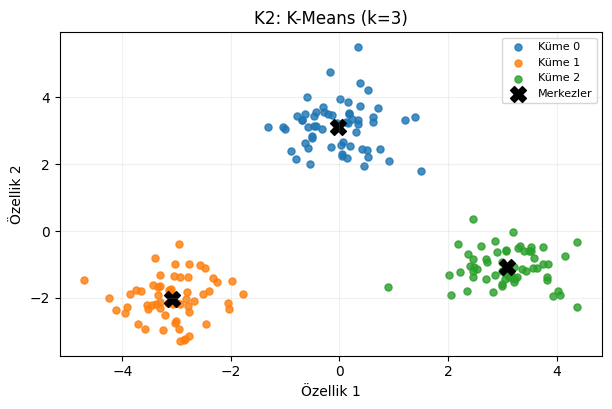

Merkezler: [[-0.03  3.12]
 [-3.08 -2.02]
 [ 3.09 -1.08]]


In [3]:
# ADIM 01: Üç küme isteyen K-Means modelini oluştur; 10 farklı başlangıç denemesi yap.
kmeans_3 = KMeans(n_clusters=3, random_state=42, n_init=10)
# ADIM 02: Modeli etiketsiz veri üzerinde eğit ve her noktaya atanan küme etiketini al.
label_km = kmeans_3.fit_predict(X_blob)
# ADIM 03: Küme etiketlerini renklerle çiz ve öğrenilen üç merkezin konumunu göster.
cluster_plot(X_blob, label_km, 'K2: K-Means (k=3)', centers=kmeans_3.cluster_centers_)
# ADIM 04: Hazırlanan grafiği görüntüle.
plt.show()
# ADIM 05: Her bir küme merkezinin x1 ve x2 koordinatlarını iki ondalıkla yazdır.
print('Merkezler:', np.round(kmeans_3.cluster_centers_,2))

## K3 · Özellikleri standartlaştırmanın etkisi

**Kavram:** Uzaklığa dayalı algoritmalarda büyük ölçekli özellik baskın olabilir. İkinci özelliği 25 ile çarpıp sonra standartlaştırmayı deneyelim.

**📝 Dene:** `25` yerine `100` kullan. Standartlaştırma neden gerekli?

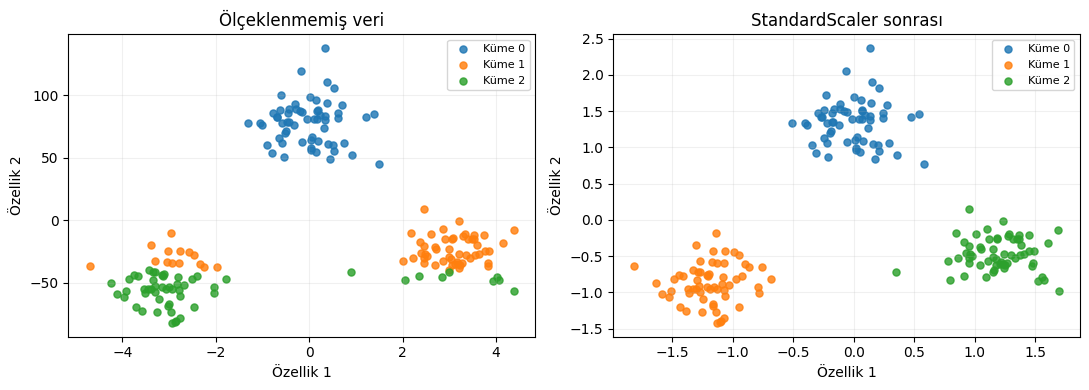

In [4]:
# ADIM 01: Orijinal veriyi bozmamak için X_blob matrisinin bir kopyasını oluştur.
X_stretched = X_blob.copy()
# ADIM 02: İkinci özelliği 25 ile çarpıp özelliklerin ölçeklerini bilerek farklılaştır.
X_stretched[:,1] *= 25
# ADIM 03: Ölçeklenmemiş veriye K-Means uygulayıp ilk küme etiketlerini al.
labels_raw = KMeans(n_clusters=3, random_state=42, n_init=10).fit_predict(X_stretched)
# ADIM 04: Her özelliği standartlaştır; özellikler arası ölçek farkını azalt.
X_scaled = StandardScaler().fit_transform(X_stretched)
# ADIM 05: Ölçeklenmiş veriye K-Means uygulayıp yeni küme etiketlerini elde et.
labels_scaled = KMeans(n_clusters=3, random_state=42, n_init=10).fit_predict(X_scaled)
# ADIM 06: İki karşılaştırma grafiği için yan yana eksenler oluştur.
fig, axs = plt.subplots(1,2,figsize=(11,4))
# ADIM 07: Ölçekleme yapılmadan bulunan kümeleri sol tarafta çiz.
cluster_plot(X_stretched, labels_raw, 'Ölçeklenmemiş veri', axs[0])
# ADIM 08: Standartlaştırmadan sonra bulunan kümeleri sağ tarafta çiz.
cluster_plot(X_scaled, labels_scaled, 'StandardScaler sonrası', axs[1])
# ADIM 09: Grafiklerin sıkışmasını önle ve karşılaştırmayı göster.
plt.tight_layout();plt.show()

## K4 · Elbow (Dirsek) yöntemi

**Kavram:** K-Means `inertia_`, noktaların merkezlerine olan kareli uzaklıklarının toplamıdır (WCSS). `k` arttıkça düşer. Belirgin azalma hızının yavaşladığı yeri inceleriz.

**📝 Dene:** `k=1,...,8` aralığını kullan. Dirsek yaklaşık nerede?

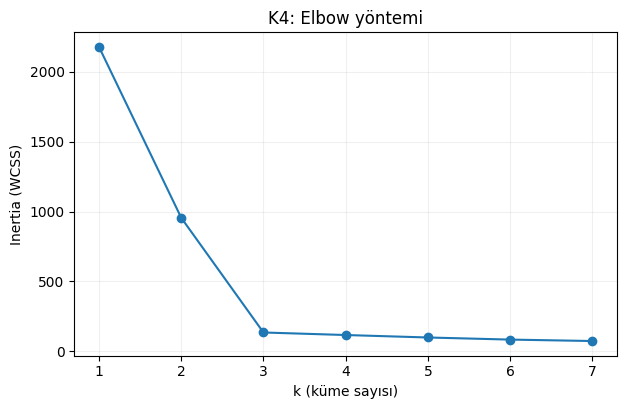

   k  Inertia
0  1   2177.0
1  2    955.0
2  3    134.7
3  4    116.5
4  5     98.9
5  6     83.9
6  7     73.6


In [5]:
# ADIM 01: Denenecek küme sayılarını 1, 2, ..., 7 olarak tanımla.
ks = range(1,8)
# ADIM 02: Her küme sayısının inertia (WCSS) değerini saklamak için boş liste oluştur.
inertias = []
# ADIM 03: Her k değeri için aynı işlemleri yapacak döngüyü başlat.
for k in ks:
    # ADIM 04: Sıradaki k ile K-Means modelini oluştur ve veri üzerinde eğit.
    km = KMeans(n_clusters=k, random_state=42, n_init=10).fit(X_blob)
    # ADIM 05: Eğitilen modelin küme içi kareli uzaklık toplamını listeye ekle.
    inertias.append(km.inertia_)
# ADIM 06: Yatayda k, dikeyde inertia olacak şekilde çizgi grafiği çiz.
plt.plot(list(ks), inertias, 'o-')
# ADIM 07: X ve Y eksenlerinin hangi büyüklükleri gösterdiğini belirt.
plt.xlabel('k (küme sayısı)');plt.ylabel('Inertia (WCSS)')
# ADIM 08: Grafiğe başlık ver ve dirsek şeklini görselleştir.
plt.title('K4: Elbow yöntemi');plt.show()
# ADIM 09: Her k için hesaplanan inertia değerlerini küçük bir tabloda göster.
print(pd.DataFrame({'k':list(ks),'Inertia':np.round(inertias,1)}))

## K5 · Silhouette skoru

**Kavram:** Silhouette, aynı kümedeki noktaların yakınlığı ile farklı kümelerin uzaklığını karşılaştırır. Değer -1 ile 1 arasındadır; yüksek değer genellikle daha iyi ayrışma demektir.

**📝 Dene:** En yüksek skoru hangi `k` sağlıyor? Bu değer her zaman en doğru küme sayısı mıdır?

 k  Silhouette
 2       0.591
 3       0.797
 4       0.638
 5       0.490
 6       0.338


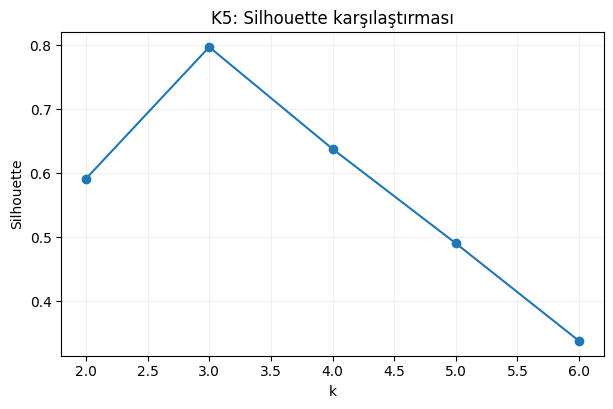

In [6]:
# ADIM 01: Farklı k değerlerine ait Silhouette sonuçlarını tutacak boş liste hazırla.
sil_results = []
# ADIM 02: Silhouette için geçerli k değerlerini 2 ile 6 arasında sırayla dene.
for k in range(2,7):
    # ADIM 03: Her k için K-Means küme etiketlerini hesapla.
    pred = KMeans(n_clusters=k, random_state=42, n_init=10).fit_predict(X_blob)
    # ADIM 04: Bu etiketlerin Silhouette skorunu hesaplayıp k ile birlikte sakla.
    sil_results.append((k, silhouette_score(X_blob,pred)))
# ADIM 05: Skorları iki sütunlu tablo hâline getir, üç ondalıkla yazdır.
print(pd.DataFrame(sil_results,columns=['k','Silhouette']).round(3).to_string(index=False))
# ADIM 06: Saklanan (k, skor) çiftlerini bir çizgi grafik olarak göster.
plt.plot([r[0] for r in sil_results],[r[1] for r in sil_results], 'o-')
# ADIM 07: Eksenleri adlandır, başlık ekle ve grafiği görüntüle.
plt.xlabel('k');plt.ylabel('Silhouette');plt.title('K5: Silhouette karşılaştırması');plt.show()

## K6 · Hiyerarşik kümeleme: Dendrogram

**Kavram:** Agglomerative yöntem başlangıçta her noktayı ayrı küme sayar, sonra kümeleri birleştirir. Dendrogram birleşmeleri gösterir.

**📝 Dene:** `method='ward'` yerine `method='single'` kullanınca ağaç nasıl değişiyor?

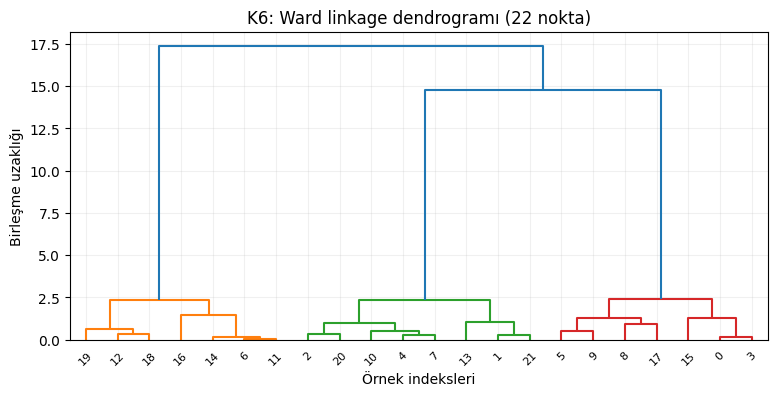

In [7]:
# ADIM 01: Dendrogramın okunaklı olması için veri kümesinden ilk 22 örneği seç.
X_small = X_blob[:22]
# ADIM 02: Seçilen örneklere Ward bağlantı yöntemiyle hiyerarşik birleştirme uygula.
Z_ward = linkage(X_small, method='ward')
# ADIM 03: Dendrogram için genişçe bir çizim alanı oluştur.
plt.figure(figsize=(9,4))
# ADIM 04: Birleşme geçmişini yapraklar (örnekler) ve dallar olarak çiz.
dendrogram(Z_ward, leaf_font_size=8)
# ADIM 05: Grafiğin hangi deneye ait olduğunu başlıkta belirt.
plt.title('K6: Ward linkage dendrogramı (22 nokta)')
# ADIM 06: Birleşme uzaklığı ve örnek indekslerini eksenlere yaz, grafiği göster.
plt.ylabel('Birleşme uzaklığı');plt.xlabel('Örnek indeksleri');plt.show()

## K7 · Agglomerative clustering ile etiket tahmini

**Kavram:** Dendrogram bir hiyerarşi sunar; `n_clusters=3` ile bu hiyerarşiyi üç gruba böleriz.

**📝 Dene:** `linkage='complete'` seç ve sonuçları karşılaştır.

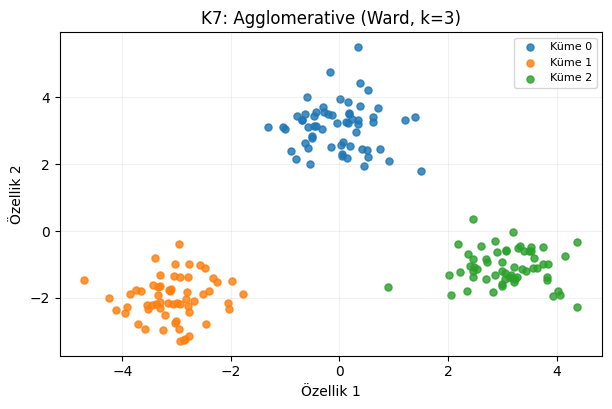

Küme büyüklükleri: {np.int64(0): np.int64(60), np.int64(1): np.int64(60), np.int64(2): np.int64(60)}


In [8]:
# ADIM 01: Ward bağlantısıyla üç küme çıkaracak agglomerative modeli oluştur.
agg = AgglomerativeClustering(n_clusters=3, linkage='ward')
# ADIM 02: Modeli eğiterek her veri noktasının küme etiketini elde et.
lab_agg = agg.fit_predict(X_blob)
# ADIM 03: Kümeleri renkli olarak iki boyutlu düzlemde çiz.
cluster_plot(X_blob, lab_agg, 'K7: Agglomerative (Ward, k=3)')
# ADIM 04: Küme grafiğini görüntüle.
plt.show()
# ADIM 05: Her etiketten kaç örnek olduğunu sayarak sözlük biçiminde göster.
print('Küme büyüklükleri:', dict(zip(*np.unique(lab_agg,return_counts=True))))

## K8 · DBSCAN: Küme, sınır, gürültü

**Kavram:** DBSCAN iki parametre kullanır: `eps` (komşuluk yarıçapı) ve `min_samples` (çekirdek nokta için yerel minimum örnek). `-1` etiketi gürültüdür.

**📝 Dene:** `eps=0.24` değerini `0.14` ve `0.40` yap. Gürültü ve küme sayısı nasıl değişiyor?

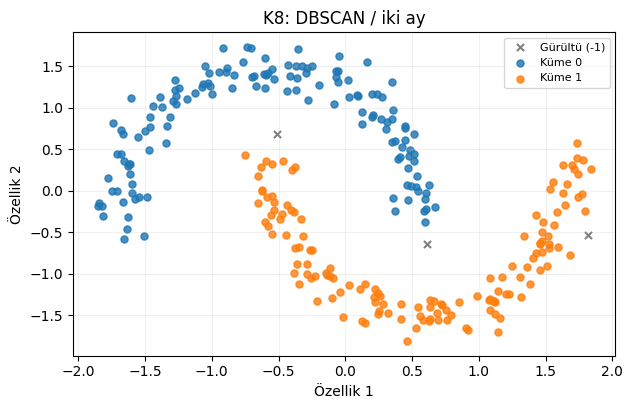

Kümeler (gürültü hariç): 2
Gürültü noktaları: 3


In [9]:
# ADIM 01: İki iç içe ay biçimli sentetik veri oluştur; gerçek etiketleri eğitim için kullanma.
X_moon, y_moon_ref = make_moons(n_samples=280, noise=0.075, random_state=42)
# ADIM 02: Uzaklıkların ölçeklerden etkilenmesini azaltmak için veriyi standartlaştır.
X_moon_s = StandardScaler().fit_transform(X_moon)
# ADIM 03: Yarıçapı eps=0.24 ve min_samples=5 olan DBSCAN modelini eğit.
lab_db = DBSCAN(eps=0.24, min_samples=5).fit_predict(X_moon_s)
# ADIM 04: DBSCAN sonucundaki kümeleri ve -1 etiketli gürültüleri çiz.
cluster_plot(X_moon_s, lab_db, 'K8: DBSCAN / iki ay')
# ADIM 05: Grafiği ekranda görüntüle.
plt.show()
# ADIM 06: -1 hariç benzersiz etiketlerin sayısını hesaplayarak küme sayısını yazdır.
print('Kümeler (gürültü hariç):', len(set(lab_db)-{-1}))
# ADIM 07: Etiketi -1 olan örnekleri say ve gürültü miktarını yazdır.
print('Gürültü noktaları:', np.sum(lab_db==-1))

## K9 · K-Means ve DBSCAN neden farklı sonuç verir?

**Kavram:** K-Means merkezlere göre, DBSCAN yoğunlukça bağlı bölgelere göre küme oluşturur. Ay biçimli veri bu farkı gösterir.

**📝 Dene:** İki sonucun ARI skorlarını (`y_moon_ref` ile) karşılaştır. Etiketleri yalnızca *sonucu değerlendirmek* için kullanıyoruz.

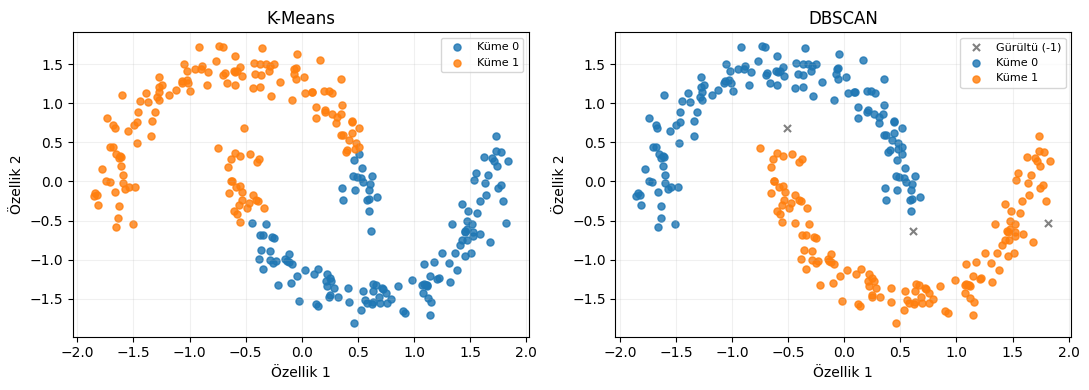

ARI K-Means: 0.468
ARI DBSCAN: 0.979


In [10]:
# ADIM 01: Aynı iki ay verisine iki kümeli K-Means uygula; kıyaslama etiketlerini hesapla.
lab_moon_km = KMeans(n_clusters=2,random_state=42,n_init=10).fit_predict(X_moon_s)
# ADIM 02: Yan yana iki grafik için figür ve eksenleri hazırla.
fig, axs = plt.subplots(1,2,figsize=(11,4))
# ADIM 03: K-Means sonucunu ilk eksende renklerle göster.
cluster_plot(X_moon_s, lab_moon_km,'K-Means', axs[0])
# ADIM 04: DBSCAN sonucunu ikinci eksende renklerle ve gürültülerle göster.
cluster_plot(X_moon_s, lab_db,'DBSCAN', axs[1])
# ADIM 05: Grafik boşluklarını ayarla ve iki sonucu birlikte göster.
plt.tight_layout();plt.show()
# ADIM 06: Sentetik gerçek etiketleri yalnız değerlendirme için kullanarak K-Means ARI hesapla.
print('ARI K-Means:',round(adjusted_rand_score(y_moon_ref,lab_moon_km),3))
# ADIM 07: Aynı gerçek etiketlerle DBSCAN ARI hesaplayıp yazdır.
print('ARI DBSCAN:',round(adjusted_rand_score(y_moon_ref,lab_db),3))

## K10 · EM/GMM ve Spectral Clustering

**Kavram:** Gaussian Mixture Model (GMM), EM ile yumuşak üyelik olasılıkları tahmin eder. Spectral Clustering, noktalar arasındaki bağlantı yapısından yararlanır.

**📝 Dene:** GMM'nin ilk nokta için verdiği üyelik olasılıklarını incele; toplamları kaç? Spectral sonucunu K-Means ile karşılaştır.

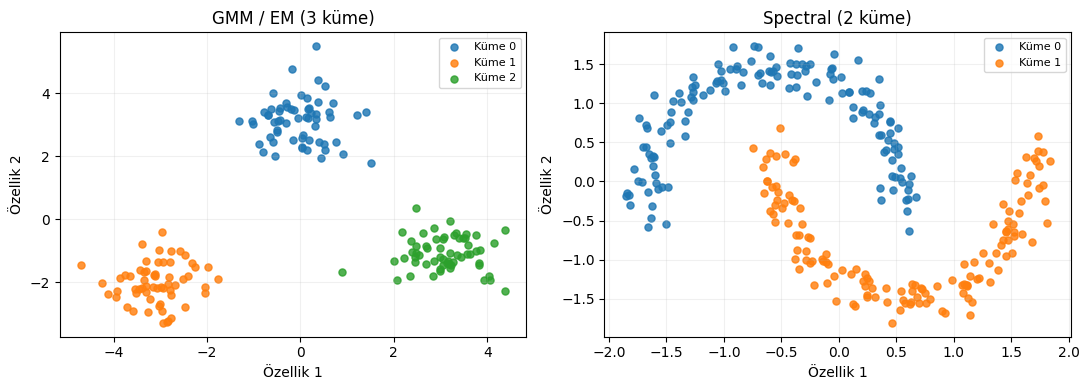

GMM ilk nokta üyelik olasılıkları: [0. 0. 1.] Toplam: 1.0
Spectral ARI: 1.0


In [11]:
# ADIM 01: Üç Gauss bileşenli Gaussian Mixture Model oluştur ve blob verisine uydur.
gmm = GaussianMixture(n_components=3,random_state=42).fit(X_blob)
# ADIM 02: Her örnek için en olası GMM bileşeni etiketini tahmin et.
lab_gmm = gmm.predict(X_blob)
# ADIM 03: İlk verinin üç bileşene ait üyelik olasılıklarını hesapla.
prob_first = gmm.predict_proba(X_blob[:1])[0]
# ADIM 04: İki ay verisi için iki küme arayan Spektral Kümeleme modelini hazırla.
spectral = SpectralClustering(n_clusters=2,affinity='nearest_neighbors',n_neighbors=10,
                              # ADIM 05: Yakın komşu sayısı, etiket atama yöntemi ve rastgelelik tohumunu belirt.
                              assign_labels='kmeans',random_state=42)
# ADIM 06: Spektral modeli eğit ve noktaların küme etiketlerini al.
lab_spec = spectral.fit_predict(X_moon_s)
# ADIM 07: GMM ve Spectral sonuçları için yan yana iki eksen aç.
fig, axs = plt.subplots(1,2,figsize=(11,4))
# ADIM 08: Sol grafikte blob verisi üzerindeki üç GMM kümesini göster.
cluster_plot(X_blob,lab_gmm,'GMM / EM (3 küme)',axs[0])
# ADIM 09: Sağ grafikte iki ay verisi üzerindeki spektral kümeleri göster.
cluster_plot(X_moon_s,lab_spec,'Spectral (2 küme)',axs[1])
# ADIM 10: Grafikleri sıkıştırmadan ekrana yansıt.
plt.tight_layout();plt.show()
# ADIM 11: İlk örneğin üyelik olasılıklarını ve toplamlarının yaklaşık 1 olduğunu yazdır.
print('GMM ilk nokta üyelik olasılıkları:', np.round(prob_first,3), 'Toplam:',round(prob_first.sum(),3))
# ADIM 12: Spektral kümelemenin gerçek sentetik etiketlerle ARI skorunu göster.
print('Spectral ARI:',round(adjusted_rand_score(y_moon_ref,lab_spec),3))

---
## K-A · Öğrenci görevi — Kümeleme karşılaştırması

**Zorluk:** Hafif kapsamlı · **Önerilen süre:** 20–30 dk · **Toplam:** 20 puan

Bir şirketin iki boyutlu müşteri davranışı verisinde alışılmadık biçimli kümeler olduğunu düşün. Sentetik *two moons* verisi üzerinde **K-Means, DBSCAN ve Agglomerative Clustering** yöntemlerini karşılaştır.

**İstenenler:**

1. Aşağıda oluşturulan `X_KA` verisini görselleştir. (2 p)
2. Veriyi **StandardScaler** ile standartlaştır ve neden gerektiğini bir cümleyle yaz. (3 p)
3. K-Means (`k=2`), DBSCAN (`eps` ve `min_samples` seçerek) ve Agglomerative (`k=2`) modellerini uygula. (6 p)
4. Üç modelin sonuçlarını aynı figürde çiz. DBSCAN için gürültü sayısını yaz. (4 p)
5. Bilinen sentetik etiketlerle **Adjusted Rand Index (ARI)** hesapla. Bu etiketleri eğitime sokma. (3 p)
6. Hangi yöntemi seçerdin? Şekil ve skorla birlikte 2–3 cümle gerekçelendir. (2 p)

**İpucu:** K9'daki kodları yeniden kullanabilirsin. Agglomerative için `linkage='single'` veya `'average'` deneyebilirsin. `eps` ile oynarken çok sayıda gürültü oluşup oluşmadığına bak.

**Beklenen teslim:** 1 karşılaştırma grafiği, kısa skor tablosu ve kısa yorum.

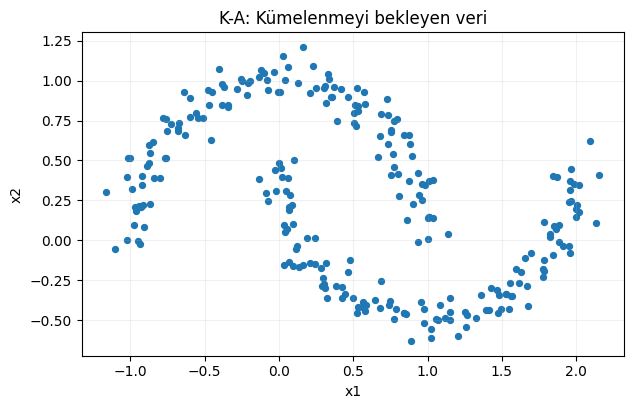

Örnek sayısı: 260


In [12]:
# K-A Başlangıç verisi: bu hücreyi çalıştırın.
# ADIM 01: Kapsamlı kümeleme sorusunda kullanılacak iki ay veri kümesini oluştur.
X_KA, y_KA_ref = make_moons(n_samples=260, noise=0.07, random_state=13)
# ADIM 02: Örneklerin x1 ve x2 koordinatlarıyla etiketsiz dağılım grafiğini çiz.
plt.scatter(X_KA[:,0], X_KA[:,1], s=18)
# ADIM 03: Grafik başlığını, eksen adlarını tanımla ve figürü göster.
plt.title('K-A: Kümelenmeyi bekleyen veri');plt.xlabel('x1');plt.ylabel('x2');plt.show()
# ADIM 04: Toplam kaç müşteri/örnek bulunduğunu ekrana yazdır.
print('Örnek sayısı:', len(X_KA))

### Eğitmen çözümü · K-A

Aşağıdaki çözüm bir **örnek** parametre seçimi gösterir. Öğrenciler farklı `eps` değerleriyle de doğru sonuçlar elde edebilir. Skor değerlendirmesinde gürültü etiketinin (`-1`) nasıl ele alındığı belirtilmelidir.

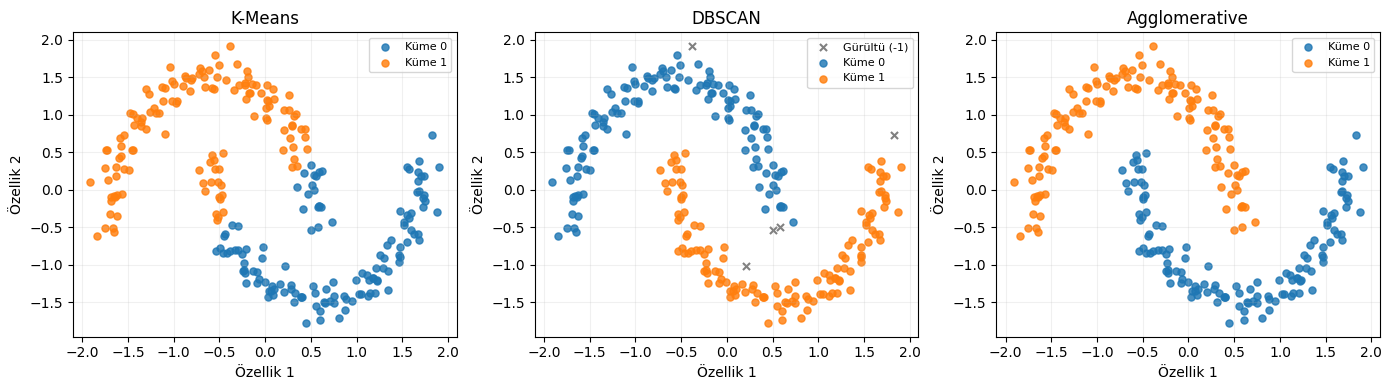

       Yöntem   ARI  Küme  Gürültü
      K-Means 0.510     2        0
       DBSCAN 0.962     2        5
Agglomerative 1.000     2        0


In [13]:
# ADIM 01: Model mesafelerini karşılaştırılabilir kılmak için görev verisini standartlaştır.
X_KA_s = StandardScaler().fit_transform(X_KA)
# ADIM 02: İki kümeli K-Means modelini eğit ve sonuç etiketlerini elde et.
ka_kmeans_labels = KMeans(n_clusters=2,random_state=42,n_init=10).fit_predict(X_KA_s)
# ADIM 03: DBSCAN modelini belirlenen eps/min_samples ile eğit ve etiketleri bul.
ka_dbscan_labels = DBSCAN(eps=0.24,min_samples=5).fit_predict(X_KA_s)
# ADIM 04: Single-linkage agglomerative modeli eğit ve iki küme etiketlerini al.
ka_agg_labels = AgglomerativeClustering(n_clusters=2,linkage='single').fit_predict(X_KA_s)
# ADIM 05: Üç modelin etiketlerini model adlarıyla eşleştirip sözlükte topla.
models_KA = {'K-Means':ka_kmeans_labels,'DBSCAN':ka_dbscan_labels,'Agglomerative':ka_agg_labels}
# ADIM 06: Üç yöntemi yan yana karşılaştırmak için üç eksenli figür oluştur.
fig, axs = plt.subplots(1,3,figsize=(14,4))
# ADIM 07: Model adları ve etiket çiftleri üzerinden görselleştirme döngüsünü başlat.
for ax,(name,labels) in zip(axs,models_KA.items()):
    # ADIM 08: Her modelin bulduğu kümeleri ilgili eksen üzerine çiz.
    cluster_plot(X_KA_s,labels,name,ax)
# ADIM 09: Grafiği düzenle ve ekrana yansıt.
plt.tight_layout();plt.show()
# ADIM 10: Her modelin ad, ARI, küme sayısı ve gürültü sayısını içeren tabloyu hazırla.
summary_KA = pd.DataFrame([{
    # ADIM 11: Model adını, sadece değerlendirme amacıyla hesaplanmış ARI skorunu kaydet.
    'Yöntem':name,'ARI':round(adjusted_rand_score(y_KA_ref,labels),3),
    # ADIM 12: -1 etiketi hariç küme sayısını ve -1 etiketli gürültü sayısını yaz.
    'Küme':len(set(labels)-{-1}),'Gürültü':int(np.sum(labels==-1))
# ADIM 13: Her model için hazırlanan sözlükleri pandas tablosuna dönüştür.
} for name,labels in models_KA.items()])
# ADIM 14: Skor ve gürültü tablosunu indeks yazdırmadan ekrana bas.
print(summary_KA.to_string(index=False))

**Eğitmen değerlendirme notu:** Ay biçimli kümeler küresel değildir; bu nedenle K-Means genellikle zayıf kalır. DBSCAN bağlı, yoğun bölgeleri bulabilir; ancak `eps` ayarına duyarlıdır. Single linkage, yoğunluk ve uzaklıklara göre ayları ayırabilir ama köprü noktaları varsa başarımı düşebilir. ARI, sentetik etiketler bilindiği için yalnızca değerlendirme amaçlıdır.

---
# BÖLÜM B — PARAMETRİK OLMAYAN YÖNTEMLER

**Amaç:** Uzaklık ölçüleri, yoğunluk tahmini, k-NN sınıflandırma/regresyon, kernel düzleştirme ve LOF ile aykırı değer tespitini denemek. Bu bölümün sonundaki NP-A ödevinde tüm adımlar öğrenciye bırakılmıştır.

## NP1 · Öklid, Manhattan ve Hamming uzaklıkları

**Kavram:** Öklid düz çizgi uzunluğu, Manhattan eksenler boyunca yol, Hamming ise uyuşmayan ayrık özellik sayısıdır.

**📝 Dene:** `a=(1,2)`, `b=(4,6)` için Öklid = 5 ve Manhattan = 7 çıktığını doğrula. İkinci noktayı `(1,6)` yapınca ne oluyor?

In [14]:
# ADIM 01: İki 2B noktanın koordinatlarını NumPy dizileri olarak tanımla.
a=np.array([1,2]); b=np.array([4,6])
# ADIM 02: İki nokta arasındaki Öklid uzaklığını (kare farkları toplamının karekökü) hesapla.
euclidean=np.linalg.norm(a-b)
# ADIM 03: Koordinatların mutlak farklarını toplayarak Manhattan uzaklığını bul.
manhattan=np.abs(a-b).sum()
# ADIM 04: Aynı uzunlukta iki ikili dizi oluştur; Hamming için karşılaştırılacak.
h1=np.array([1,0,1,1,0]); h2=np.array([1,1,0,1,0])
# ADIM 05: İkili dizilerde eşleşmeyen konumların sayısını hesapla.
hamming=np.count_nonzero(h1 != h2)
# ADIM 06: Üç uzaklık türünün sonuçlarını tek satırda ekrana yazdır.
print('Öklid:',euclidean,'Manhattan:',manhattan,'Hamming:',hamming)
# ADIM 07: Hamming uzaklığındaki farklı konumları görmek için eşleşmeleri yan yana yazdır.
print('Hamming karşılaştırması:',list(zip(h1,h2)))

Öklid: 5.0 Manhattan: 7 Hamming: 2
Hamming karşılaştırması: [(np.int64(1), np.int64(1)), (np.int64(0), np.int64(1)), (np.int64(1), np.int64(0)), (np.int64(1), np.int64(1)), (np.int64(0), np.int64(0))]


## NP2 · Mahalanobis uzaklığı

**Kavram:** Mahalanobis, kovaryans yapısını hesaba katar. Genel formül `sqrt((x-y)^T S^{-1}(x-y))` şeklindedir.

**📝 Dene:** `S` matrisini birim matris (`np.eye(2)`) yap. Mahalanobis neden Öklid'e eşit olur?

In [15]:
# ADIM 01: Örneklerin 2B koordinatlarını kayan noktalı sayılarla tanımla.
x=np.array([3.,2.]); y=np.array([1.,1.])
# ADIM 02: Özellik varyans ve korelasyonlarını temsil eden kovaryans matrisini belirle.
S=np.array([[4.,1.5],[1.5,1.]])
# ADIM 03: İki noktanın koordinat farklarını hesapla.
delta=x-y
# ADIM 04: Mahalanobis formülünü kovaryans matrisinin tersiyle uygula.
mahalanobis=np.sqrt(delta.T @ np.linalg.inv(S) @ delta)
# ADIM 05: Karşılaştırma için aynı noktaların Öklid uzaklığını yazdır.
print('Öklid:',round(np.linalg.norm(delta),3))
# ADIM 06: Hesaplanan Mahalanobis uzaklığını üç ondalık basamakla göster.
print('Mahalanobis:',round(mahalanobis,3))
# ADIM 07: Kullanılan kovaryans matrisini ekrana yazdır.
print('Kovaryans matrisi:',S)

Öklid: 2.236
Mahalanobis: 1.069
Kovaryans matrisi: [[4.  1.5]
 [1.5 1. ]]


## NP3 · Histogramla yoğunluk tahmini

**Kavram:** Histogramda `density=True` kullanılırsa çubukların **alanları toplamı 1** olur; yükseklikler yalnızca veri sayısı değildir.

**📝 Dene:** Bin sayısını 5, 12 ve 25 yap. Küçük aralıklar neden daha sivri bir grafik üretiyor?

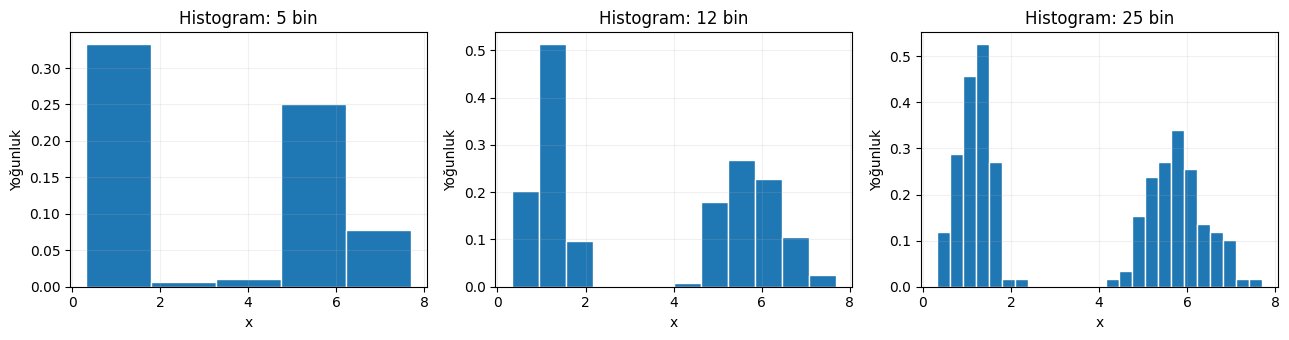

In [16]:
# ADIM 01: Tekrarlanabilir rasgele sayı üretici oluştur.
rng=np.random.default_rng(42)
# ADIM 02: İki normal dağılımdan toplam 200 nokta üretip tek diziye birleştir.
values=np.concatenate([rng.normal(1.2,.45,100), rng.normal(5.8,.65,100)])
# ADIM 03: 5, 12 ve 25 aralıklı histogramları karşılaştırmak üzere üç eksen hazırla.
fig,axs=plt.subplots(1,3,figsize=(13,3.5))
# ADIM 04: Eksenleri farklı bin sayılarıyla eşleştiren döngüyü başlat.
for ax,bins in zip(axs,[5,12,25]):
    # ADIM 05: Her eksene normalleştirilmiş yoğunluk histogramını çiz.
    ax.hist(values,bins=bins,density=True,edgecolor='white')
    # ADIM 06: Histogram başlığını ve eksen etiketlerini belirt.
    ax.set(title=f'Histogram: {bins} bin',xlabel='x',ylabel='Yoğunluk')
# ADIM 07: Grafikleri yan yana düzenle ve görüntüle.
plt.tight_layout();plt.show()

## NP4 · KDE ve k-NN yoğunluk tahmini

**Kavram:** KDE her noktanın etrafına yumuşak bir kernel yerleştirir; `bandwidth` küçükse daha sivri eğri oluşur. k-NN yoğunluk tahmini ise k'nci komşuya olan uzaklığı kullanır.

**📝 Dene:** `bandwidth=0.25` ve `0.8` için farkı gözlemle; k-NN yoğunluğunda `k=3` yerine `k=7` kullan.

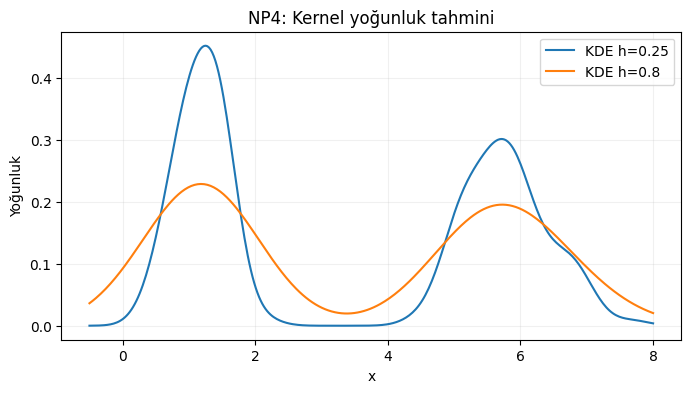

x=1.7, k=3, k. komşuya uzaklık=0.050, k-NN yoğunluğu=0.150


In [17]:
# ADIM 01: Yoğunluğu hesaplamak istediğimiz x noktalarından 350 satırlık bir sorgu matrisi oluştur.
grid=np.linspace(-.5,8,350).reshape(-1,1)
# ADIM 02: KDE eğrilerini göstermek için yeni figür aç.
plt.figure(figsize=(8,4))
# ADIM 03: 0.25 ve 0.8 bant genişliklerinin her birini ayrı ayrı dene.
for bandwidth in [0.25,0.8]:
    # ADIM 04: Gaussian KDE modelini oluştur, mevcut eğitim değerlerine uydur.
    kde=KernelDensity(kernel='gaussian',bandwidth=bandwidth).fit(values.reshape(-1,1))
    # ADIM 05: Log yoğunluk skorlarına üstel uygulayarak normal yoğunluk değerlerini bul.
    density=np.exp(kde.score_samples(grid))
    # ADIM 06: Aynı grafik üzerinde bant genişliğine ait KDE eğrisini çiz.
    plt.plot(grid[:,0],density,label=f'KDE h={bandwidth}')
# ADIM 07: Başlıkla x ve yoğunluk eksenlerini tanımla.
plt.title('NP4: Kernel yoğunluk tahmini');plt.xlabel('x');plt.ylabel('Yoğunluk')
# ADIM 08: İki bandwidth etiketini açıklamada göster ve grafiği aç.
plt.legend();plt.show()
# ADIM 09: k-NN yoğunluğunu hesaplayacağımız nokta x=1.7 ve komşu sayısı k=3 olsun.
query=1.7; k=3
# ADIM 10: Bu noktaya tüm örnek uzaklıklarını bul ve küçükten büyüğe sırala.
sorted_distances=np.sort(np.abs(values-query))
# ADIM 11: Üçüncü en yakın komşu uzaklığını 0 tabanlı k-1 indeksinden al.
dk=sorted_distances[k-1]
# ADIM 12: Bir boyutta k/(2*N*dk) k-NN yoğunluk formülünü uygula.
p_knn=k/(2*len(values)*dk)
# ADIM 13: Sorgu noktasını, komşu uzaklığını ve yoğunluk tahminini ekrana yazdır.
print(f'x={query}, k={k}, k. komşuya uzaklık={dk:.3f}, k-NN yoğunluğu={p_knn:.3f}')

## NP5 · k-NN sınıflandırma ve komşu oylaması

**Kavram:** En yakın `k` örneğin sınıf etiketleri arasında çoğunluk oyu alınır. `k=1` dalgalı, büyük `k` daha düz sınırlar üretebilir.

**📝 Dene:** `n_neighbors=1` yerine `11` kullan; test noktası için komşu oylarını ve tahmini sınıfı karşılaştır.

En yakın indeksler: [ 77 107 105  17  23]
Komşu sınıfları: [0 0 1 0 0]
Tahmin sınıfı: 0
Sınıf oranları: [0.8 0.2]


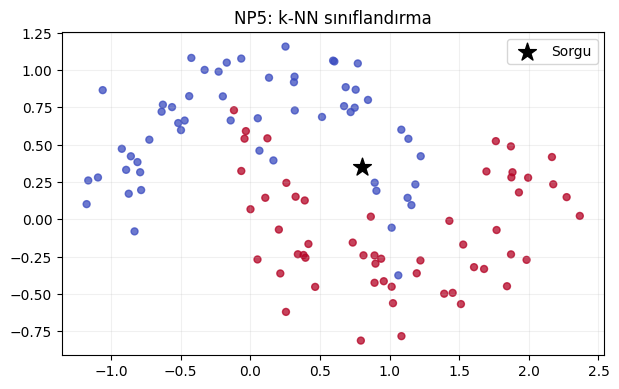

In [18]:
# ADIM 01: İki sınıflı sentetik two-moons veri kümesi oluştur.
X_NP5,y_NP5=make_moons(n_samples=110,noise=.18,random_state=3)
# ADIM 02: En yakın 5 komşuyla karar veren k-NN sınıflandırıcısını eğit.
knn_cls=KNeighborsClassifier(n_neighbors=5).fit(X_NP5,y_NP5)
# ADIM 03: Etiketini tahmin edeceğimiz yeni bir sorgu noktası belirle.
query_np5=np.array([[0.8,0.35]])
# ADIM 04: Sorguya en yakın 5 noktanın uzaklıklarını ve indekslerini getir.
dist, ind = knn_cls.kneighbors(query_np5)
# ADIM 05: En yakın eğitim örneklerinin indekslerini yazdır.
print('En yakın indeksler:',ind[0])
# ADIM 06: Bu komşuların gerçek sınıf etiketlerini göster; çoğunluk oylamasını izle.
print('Komşu sınıfları:',y_NP5[ind[0]])
# ADIM 07: k-NN modelinin yeni örnek için seçtiği sınıfı yazdır.
print('Tahmin sınıfı:',knn_cls.predict(query_np5)[0])
# ADIM 08: Komşu etiketlerinden türeyen sınıf oranlarını hesaplayıp yazdır.
print('Sınıf oranları:',np.round(knn_cls.predict_proba(query_np5)[0],2))
# ADIM 09: Eğitim noktalarını gerçek sınıflara göre renklendirerek çiz.
plt.scatter(X_NP5[:,0],X_NP5[:,1],c=y_NP5,cmap='coolwarm',s=25,alpha=.75)
# ADIM 10: Siyah yıldızla sınıflandırılacak sorgu noktasını grafiğe yerleştir.
plt.scatter(query_np5[:,0],query_np5[:,1],marker='*',s=180,c='black',label='Sorgu')
# ADIM 11: Grafiği başlık ve lejant ile birlikte göster.
plt.title('NP5: k-NN sınıflandırma');plt.legend();plt.show()

## NP6 · k-NN regresyon ve kernel smoother

**Kavram:** k-NN regresyon en yakın komşuların çıktı ortalamasını alır. Kernel smoother (Nadaraya–Watson) uzak noktalara daha düşük ağırlık verir.

**📝 Dene:** `k=5` ve `k=25` için çizgileri karşılaştır. Kernel bant genişliği `h=0.3` veya `h=1.1` olursa ne değişir?

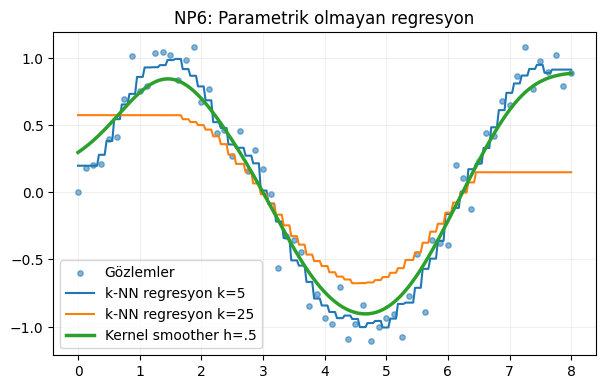

In [19]:
# ADIM 01: Sentetik regresyon değerlerini tekrarlanabilir üretmek için tohum belirle.
rng=np.random.default_rng(7)
# ADIM 02: 0 ile 8 arasında düzenli 65 giriş noktası oluştur.
X_reg=np.linspace(0,8,65)
# ADIM 03: Gerçek sinüs eğrisine rastgele gürültü ekleyerek hedef değerleri oluştur.
y_reg=np.sin(X_reg)+rng.normal(0,.18,len(X_reg))
# ADIM 04: Tahmin çizgileri için daha sık aralıklı 260 sorgu noktası hazırla.
grid_reg=np.linspace(0,8,260)
# ADIM 05: k=5 olan k-NN regresyon modelini eğit.
reg5=KNeighborsRegressor(n_neighbors=5).fit(X_reg.reshape(-1,1),y_reg)
# ADIM 06: k=25 olan k-NN regresyon modelini eğit; k etkisi karşılaştırılacak.
reg25=KNeighborsRegressor(n_neighbors=25).fit(X_reg.reshape(-1,1),y_reg)

# ADIM 07: Gaussian çekirdekli yerel ağırlıklı ortalama fonksiyonunu tanımla.
def gaussian_kernel_smoother(query_x,train_x,train_y,h=.5):
    # ADIM 08: Bütün sorgu x değerlerinin bütün eğitim x değerlerine farklarını h ile ölçekle.
    dist=(query_x[:,None]-train_x[None,:])/h
    # ADIM 09: Gaussian ağırlıklarını exp(-0.5*uzaklık^2) ile hesapla.
    weights=np.exp(-.5*dist**2)
    # ADIM 10: Ağırlıklı çıktıları ağırlık toplamına bölerek her sorgu için tahmini döndür.
    return (weights @ train_y)/weights.sum(axis=1)

# ADIM 11: h=0.5 kullanarak tüm sorgu noktaları için kernel regresyon eğrisini bul.
kernel_y=gaussian_kernel_smoother(grid_reg,X_reg,y_reg,h=.5)
# ADIM 12: Gürültülü gözlem noktalarını yarı saydam olarak çiz.
plt.scatter(X_reg,y_reg,s=15,alpha=.55,label='Gözlemler')
# ADIM 13: k=5 regresyon tahminlerini birinci eğri olarak çiz.
plt.plot(grid_reg,reg5.predict(grid_reg.reshape(-1,1)),label='k-NN regresyon k=5')
# ADIM 14: k=25 regresyon tahminlerini ikinci eğri olarak çiz.
plt.plot(grid_reg,reg25.predict(grid_reg.reshape(-1,1)),label='k-NN regresyon k=25')
# ADIM 15: Kernel smoother tahminlerini üçüncü eğri olarak çiz.
plt.plot(grid_reg,kernel_y,label='Kernel smoother h=.5',linewidth=2.5)
# ADIM 16: Grafiğe başlık ekle, yöntemleri lejantla ayır ve grafiği göster.
plt.title('NP6: Parametrik olmayan regresyon');plt.legend();plt.show()

## NP7 · LOF (Local Outlier Factor) ile anomali

**Kavram:** LOF bir noktanın yerel yoğunluğunu komşularının yoğunluğuyla karşılaştırır. `-1` anomali etiketidir. Aykırı noktalar çok uzak olsa bile model eşik ayarına duyarlıdır.

**📝 Dene:** `n_neighbors=15` değerini `5` ve `30` yap. Tahmin edilen aykırı değer sayısı neden değişiyor?

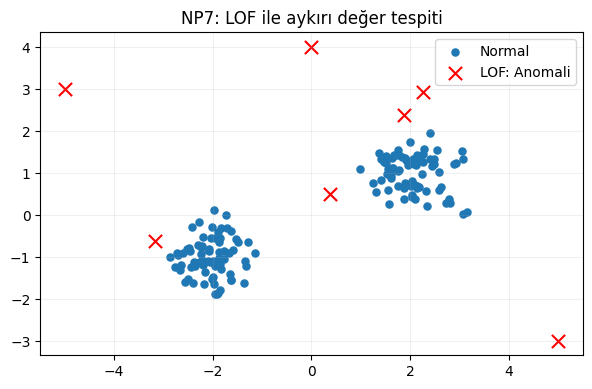

LOF tarafından anomali seçilen örnek sayısı: 7


In [20]:
# ADIM 01: İki yoğun veri bölgesinden toplam 150 normal örnek oluştur.
X_in, _=make_blobs(n_samples=150, centers=[(-2,-1),(2,1)],cluster_std=[.45,.5],random_state=42)
# ADIM 02: Üç belirgin uzak noktayı aykırı örnek olarak ayrı tanımla.
X_out=np.array([[-5,3],[0,4],[5,-3]])
# ADIM 03: Normal ve aykırı örnekleri tek bir veri matrisinde birleştir.
X_lof=np.vstack([X_in,X_out])
# ADIM 04: 15 komşulu LOF algoritmasını kur; beklenen anomali oranını %4 belirle.
lof=LocalOutlierFactor(n_neighbors=15,contamination=.04)
# ADIM 05: LOF modelini bütün veri üzerinde çalıştır; normal=1, anomali=-1 etiketlerini al.
lab_lof=lof.fit_predict(X_lof)
# ADIM 06: Normal olarak tahmin edilen noktaları seçen mantıksal maske oluştur.
normal=lab_lof==1
# ADIM 07: Normal noktaları çizim üzerinde göster.
plt.scatter(X_lof[normal,0],X_lof[normal,1],s=26,label='Normal')
# ADIM 08: Anomali tahmini verilen noktaları kırmızı çarpılarla çiz.
plt.scatter(X_lof[~normal,0],X_lof[~normal,1],c='red',marker='x',s=90,label='LOF: Anomali')
# ADIM 09: Anomali görselini başlık ve lejant ile aç.
plt.title('NP7: LOF ile aykırı değer tespiti');plt.legend();plt.show()
# ADIM 10: LOF tarafından -1 olarak işaretlenen örnek sayısını ekrana yazdır.
print('LOF tarafından anomali seçilen örnek sayısı:',np.sum(~normal))

---
## NP-A · Öğrenci görevi — k-NN ile şarap sınıflandırma

**Zorluk:** Hafif kapsamlı · **Önerilen süre:** 20–30 dk · **Toplam:** 20 puan

scikit-learn'ün yerleşik Wine veri kümesini kullanarak örneklerin üç sınıftan hangisine ait olduğunu k-NN ile tahmin et.

**İstenenler:**

1. Özellik ve sınıf sayılarını yazdır; `train / validation / test` olarak ayır (ayırma kodu verildi). (2 p)
2. **StandardScaler'ı yalnızca train üzerinde fit et**; validation ve test'i aynı scaler ile dönüştür. (4 p)
3. `k ∈ {1,3,5,7,9}` ve iki uzaklık türü (Öklid: `p=2`, Manhattan: `p=1`) dene. (6 p)
4. **Validation accuracy** değerlerini tabloya yaz. En iyi kombinasyonu seç. (3 p)
5. Seçilen modeli **test kümesinde yalnızca bir kez** değerlendir ve karışıklık matrisini çiz. (3 p)
6. Ölçeklendirme k-NN için neden önemli? 2 cümleyle açıkla. (2 p)

**Not:** Test sonuçlarına göre hiperparametre değiştirmeyin. Amaç veri sızıntısını (data leakage) önlemek ve doğru değerlendirme akışı kurmaktır.

**Beklenen teslim:** Validation sonuç tablosu, en iyi `k` ve `p`, test accuracy, confusion matrix ve kısa yorum.

In [21]:
# NP-A Başlangıç: veriyi bölme hazır; test etiketlerine seçim sırasında bakmayın.
# ADIM 01: Scikit-learn içindeki Wine sınıflandırma veri kümesini yükle.
wine=load_wine()
# ADIM 02: Özellik matrisini sütun adlarıyla birlikte pandas DataFrame olarak oluştur.
X_NPA=pd.DataFrame(wine.data, columns=wine.feature_names)
# ADIM 03: Üç sınıfa ait hedef etiket dizisini hazırla.
y_NPA=wine.target
# ADIM 04: Önce veriyi geliştirme (%80) ve test (%20) parçalarına ayır.
X_develop, X_test, y_develop, y_test = train_test_split(
    # ADIM 05: Sınıf oranlarını koruyacak şekilde stratify uygula ve bölmeyi tekrarlanabilir yap.
    X_NPA, y_NPA, test_size=.20, stratify=y_NPA, random_state=42)
# ADIM 06: Geliştirme verisini eğitim ve validation olmak üzere yeniden ayır.
X_train, X_val, y_train, y_val = train_test_split(
    # ADIM 07: İkinci ayırımda da sınıf oranlarını koruyup sabit tohum kullan.
    X_develop,y_develop,test_size=.25,stratify=y_develop,random_state=42)
# ADIM 08: Özellik sütunu ve hedef sınıf sayısını hesaplayıp yazdır.
print('Özellik sayısı:',X_NPA.shape[1],'Sınıf sayısı:',len(np.unique(y_NPA)))
# ADIM 09: Train, validation ve test kümelerindeki örnek sayılarını ekrana yazdır.
print('train / validation / test:',len(X_train),len(X_val),len(X_test))

Özellik sayısı: 13 Sınıf sayısı: 3
train / validation / test: 106 36 36


### Eğitmen çözümü · NP-A

Önemli değerlendirme kriteri: Scaler'ın `fit` işlemi yalnızca eğitim kümesinde yapılmalı; hiperparametre seçiminde test kümesi kullanılmamalıdır.

In [22]:
# ADIM 01: Ölçekleyicinin ortalama ve sapma parametrelerini SADECE eğitim verisinden öğren.
scaler_NPA=StandardScaler().fit(X_train)
# ADIM 02: Eğitim verisini öğrenilen ölçekleme parametreleriyle dönüştür.
X_train_s=scaler_NPA.transform(X_train)
# ADIM 03: Doğrulama verisini yeniden fit yapmadan aynı parametrelerle dönüştür.
X_val_s=scaler_NPA.transform(X_val)
# ADIM 04: Test verisini de fit yapmadan aynı parametrelerle dönüştür; veri sızıntısını önle.
X_test_s=scaler_NPA.transform(X_test)
# ADIM 05: Tüm hiperparametre denemeleri için boş sonuç listesi aç.
results=[]
# ADIM 06: Manhattan (p=1) ve Öklid (p=2) uzaklıklarını sırayla dene.
for p in [1,2]:
    # ADIM 07: k=1,3,5,7,9 komşu sayılarını sırayla dene.
    for k in [1,3,5,7,9]:
        # ADIM 08: Sıradaki k ve p ile k-NN sınıflandırıcısını oluştur.
        m=KNeighborsClassifier(n_neighbors=k,p=p)
        # ADIM 09: Modeli yalnızca eğitim kümesinde öğren.
        m.fit(X_train_s,y_train)
        # ADIM 10: Doğrulama kümesi için sınıf tahminlerini hesapla.
        val_pred=m.predict(X_val_s)
        # ADIM 11: k, p, metrik adı ve doğrulama başarımını sonuç listesine ekle.
        results.append({'k':k,'p':p,'metric':'Manhattan' if p==1 else 'Öklid',
                        # ADIM 12: Validation accuracy değerini gerçek doğrulama etiketleriyle hesaplayıp sözlüğe ekle.
                        'validation_accuracy':accuracy_score(y_val,val_pred)})
# ADIM 13: Sonuçları tabloya dönüştür; önce accuracy büyük, eşitlikte küçük k/p öne gelsin.
results_df=pd.DataFrame(results).sort_values(['validation_accuracy','k','p'],ascending=[False,True,True])
# ADIM 14: Tüm denemelerin doğrulama tablosunu ekrana yazdır.
print(results_df.to_string(index=False))
# ADIM 15: En üstteki satırın k/p kombinasyonunu en iyi aday olarak seç.
best_NPA=results_df.iloc[0]
# ADIM 16: Seçilen adayın hiperparametrelerini ve doğrulama doğruluğunu ekrana yazdır.
print('En iyi:',best_NPA[['k','p','validation_accuracy']].to_dict())

 k  p    metric  validation_accuracy
 5  1 Manhattan             1.000000
 7  1 Manhattan             1.000000
 7  2     Öklid             1.000000
 9  1 Manhattan             1.000000
 9  2     Öklid             1.000000
 3  2     Öklid             0.972222
 5  2     Öklid             0.972222
 1  1 Manhattan             0.944444
 1  2     Öklid             0.944444
 3  1 Manhattan             0.944444
En iyi: {'k': 5, 'p': 1, 'validation_accuracy': 1.0}


TEST accuracy: 1.0


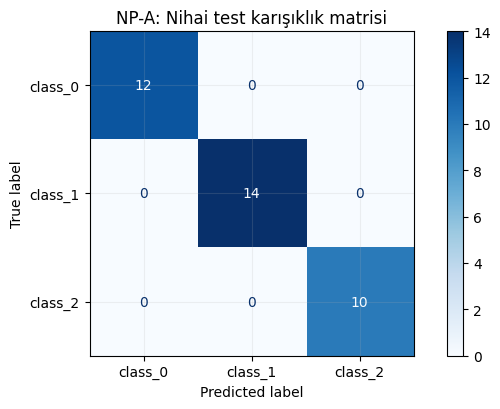

In [23]:
# ADIM 01: Doğrulamada seçilen en iyi k ve p ile nihai k-NN modelini kur.
best_model_NPA=KNeighborsClassifier(n_neighbors=int(best_NPA['k']),p=int(best_NPA['p']))
# ADIM 02: Yalnızca eğitim verisini kullanarak en iyi ayarlı modeli eğit.
best_model_NPA.fit(X_train_s,y_train)
# ADIM 03: Testi model seçimi bittikten sonra bir kez tahmin et.
y_test_pred=best_model_NPA.predict(X_test_s)
# ADIM 04: Test tahminleriyle gerçek etiketleri karşılaştırarak doğruluğu yazdır.
print('TEST accuracy:',round(accuracy_score(y_test,y_test_pred),3))
# ADIM 05: Her sınıf için doğru/yanlış tahmin sayılarını karışıklık matrisinde göster.
ConfusionMatrixDisplay.from_predictions(y_test,y_test_pred,display_labels=wine.target_names,cmap='Blues')
# ADIM 06: Son grafiğin başlığını ekle, boşlukları ayarla ve çizimi göster.
plt.title('NP-A: Nihai test karışıklık matrisi');plt.tight_layout();plt.show()

**Eğitmen değerlendirme notu:** Ölçeklendirme, farklı ölçekteki kimyasal özelliklerin mesafeyi tek başına belirlemesini azaltır. Validation üzerindeki eşitliklerde daha küçük `k` ya da daha büyük `k` seçimi açık bir bağlayıcı kuralla yapılabilir; burada tabloda küçük `k`, ardından küçük `p` önce seçiliyor. Test sonucuna bakılarak yeniden hiperparametre aranmamalı.

---
## Laboratuvar kapanışı — Kısa kontrol

1. K-Means ile DBSCAN'in küme varsayımları neden farklıdır?
2. Elbow ve Silhouette aynı `k` değerini vermek zorunda mı?
3. Agglomerative yönteminde *linkage* neyi değiştirir?
4. Öklid, Manhattan, Hamming ve Mahalanobis hangi tür benzerlikleri ölçer?
5. KDE'de `bandwidth` artarsa eğri nasıl değişir?
6. k-NN sınıflandırma ile k-NN regresyonun çıktısı nasıl farklıdır?
7. LOF değeri yüksek olan bir nokta için ne söyleyebiliriz?
8. Model seçimi neden test kümesi üzerinde yapılmamalıdır?

**Teslim:** K-A ve NP-A görevlerini, kod + grafik + yorumlarıyla tamamlanmış `.ipynb` dosyası olarak yükleyin.

**Kaynak:** Ethem Alpaydın, *Introduction to Machine Learning*, Bölüm 8 (parametrik olmayan yöntemler); kümeleme uygulamalarında scikit-learn API. Bu notebook, ünitedeki kavramları öğretmek üzere yeni oluşturulmuş örnekler içerir.